# chip_07 — six hanger λ/4 resonators on one feedline (legacy QWri), rebuilt on the Quantcore PDK

## 1 · What the chip is

**Source:** `components/python/chip_07_resonators.py` (`create_test_chip`, original author, May 2024; output
`chip_07_TLW4.0_6x_dec24`), Quantcore internal. Spec: `docs/designs/legacy/chip_07_resonators.md`.

A 7.5 × 7.5 mm resonator test chip: a 10/6 µm feedline between two bond pads with six `Coupled Resonator`s
(λ/4, shorted at the coupler), three above and three below, coupled over 200–600 µm at 4–6 µm. Targets from the
code comments and the etched labels "50" … "65": 5.0, 5.25, 5.5, 6.0, 6.25, 6.5 GHz. Six flux-hole arrays line
the feedline; the chip label "WSK_TLW07".

| | the rebuild keeps (source-faithful) | the Quantcore PDK changes |
|---|---|---|
| resonators | the six `Coupled Resonator`s with the legacy parameters (`CoupledResonator`), legacy positions relative to the feedline | drawn on 1/0 (R8/R9/R12 were on the legacy second-metal layers; 3/0 is derived by the PDK) |
| feedline, pads | "Connector Pad 2" geometry (`BondPad`), 10/6 µm CPW (`CpwSegment`) | pads with their outer etch **`pad_edge` = 100 µm** from the die edge (legacy: at the edge): feedline 5250 → 5050 µm |
| cheese | the source's own six flux-hole rows beside the feedline (`FluxHoleArray`) | the source's holes stay (the end rows FH0 / FH5 lose the 2 and 4 holes per row that the moved pads now cover), and the PDK cheese covers the rest of the die (`cheese: "chip"`: 5 µm squares with 20 µm gaps, at least 4 µm from the 3/0 keep-outs, which cover every structure and hole row, so no PDK hole touches one) |
| placement | everything relative to the feedline | the circuit **centred in the die** (it sat 150 µm low: the top resonators are shorter) |
| frame | — | the PDK die frame (dicing L markers, alignment grids, device ID `CHIP07`) instead of the legacy corner `Marker`s |
| junctions | — (no qubits on this chip) | — |

**Reproduced exactly** (XOR 0 µm² against the author's own PCells, run read-only through `tests/legacy_ref`,
step 14): the six resonators, the flux-hole arrays FH1–FH4 (FH0 / FH5 minus the holes under the moved pads) and the seven text labels. The header's "10 resonators"
and "test junctions" are stale (six resonators; the test-pad block is commented out).

### Changes after design review (2026-11-03)

- **#12 targets and lengths — noted** (review note: "yes they were simulated without the claws"). The legacy lengths and
  targets come from simulations of bare λ/4 resonators, without an Xmon claw at the open end. This chip's six
  resonators are bare (no qubits), so they are the case those simulations describe; the LOM and design 14's
  calibration still sit 0.15–0.26 GHz above the targets written into this chip for the same lengths (the targets
  assumed a slightly longer effective length). Lengths kept as in the source; on a chip where the same lengths end
  on an Xmon claw (d14's bottom row, chips 01–05) the claw pulls them a further 0.6–1.2 GHz down.
- No geometry change; nothing to re-run for this note.

### PDK conformance pass (notebooks-legacy, 2026-11-03; pad rule 100 µm, 2026-11-10)

- **Pads:** the two bond pads are placed first with `edge="auto"` (outer etch `get_pdk().frame.pad_edge` = 100 µm
  from the die edge, the PDK pad rule; 25 µm until 2026-11-10) and the feedline spans between their ports: 5050 µm
  instead of the legacy 5250 µm (the legacy pads ran to the die edge). DRC `pad_edge` warnings: 2 → 0.
- **Holes under the pads:** the moved pads cover the outer ends of the first and last flux-hole rows; FH0 and FH5
  keep only the holes beside the feedline (`L.clip_holes`, legacy grid): 2 and 4 holes per row fewer.
- **Centring:** the circuit (labels excluded from the measure, moved with it) sat 150 µm below the die centre (the
  three resonators above the feedline are shorter than the three below); `L.center_circuit` moves everything up by
  150.5 µm. The feedline is now at y = 3900.5 µm. The legacy reference in step 14 is moved by the same shift.
- **Cheese:** the source draws its own flux holes (two rows of 5 µm squares beside the feedline, `flux_holes` in
  `chip_07_resonators.py`); they stay as drawn, and the PDK cheese covers the rest of the die (`cheese: "chip"`): 5 µm squares with 20 µm gaps wherever the ground is at least 4 µm from the 3/0 keep-outs, which cover every structure, so no hole touches one.
- Educative layout: one step per stage (die → pads → resonators → holes and labels → centring → DRC → LOM → FEM →
  iterate → export → snapshots).

## 2 · Setup and the Quantcore PDK

The helpers keep the cells short: `_common` (`C`) holds the netlist / LOM / FEM-export / snapshot helpers and
the PDK checks shared by every design notebook; `_legacy` (`L`) maps the legacy PCell parameters onto the
Quantcore cells, draws the legacy reference with the author's own legacy code (read-only), and holds the step
helpers of these notebooks. `LIVE` decides whether the design is pushed to a running KLayout (`QCC_LIVE=0`
for batch runs: nothing reaches KLayout).

In [2]:
%config InlineBackend.figure_formats = ["png"]
import os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                       # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
sys.path.insert(0, str(ROOT / "examples" / "designs" / "legacy"))
LIVE = os.environ.get("QCC_LIVE", "1") == "1"       # live KLayout by default; QCC_LIVE=0 for batch runs
import _common as C                                  # netlist / LOM / FEM-export / snapshot / PDK-check helpers
import _legacy as L                                  # legacy frame shift, parameter mapping, legacy reference, steps
import _legacy_b as LB                               # chip_07 tables and legacy reference
from IPython.display import Image, Markdown, display
from quantcore_circuits.designer import Designer
from quantcore_circuits.pdk import get_pdk

ID, OUT = "chip_07_resonators", Path("examples/designs/legacy")

The PDK facts this rebuild uses, read from `get_pdk()` (nothing below is typed in by hand). The rules that
change a legacy chip are the **pad rule** (step 4), the **junction rule** (step 5), the **3/0 keep-out**
and the **cheese rule** (drawn by the build, step 13) and the centring of the content (step 6).

In [3]:
CHEESE_NOTE = 'chip — the PDK cheese over the whole die; the flux-hole rows the source etches beside the feedline (FluxHoleArray) stay'
display(Markdown(L.pdk_facts_md(CHEESE_NOTE)))

| PDK item | value |
|---|---|
| PDK | `quantcore_nb_sapphire_v1` (version 3) |
| stack | sapphire, 650 µm, ε_r 10.25; Nb film (sheet metal in the FEM exports, 0.2 µm for the analytic CPW formulas) |
| CPW default | 10 µm centre, 6 µm gap, bends r = 100 µm |
| die frame | L-shaped dicing markers 25 µm wide (250 µm legs, 1000/0), 3 × 3 alignment grids (1001/0) in 500 µm corner squares, design area 100 µm inside the die edge, device ID optional (bottom centre, or beside the pads) |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (the design-area margin) from the die edge, whatever the original did (`edge="auto"`, DRC design warning `pad_edge`) |
| junction rule | Nb/AlOx/Nb trilayer, Δ = 1.4 meV (I_c·R_n = πΔ/2e), R_n 40–50 kΩ (nominal 45), qubits 4–8 GHz; R_n·A 13500 Ω·µm² and C_J 50 fF/µm² assumed; cells `Quantcore Junction` / `Quantcore Squid` (DRC design warnings `pdk_rn`, `pdk_fq`: flagged, never retuned) |
| 3/0 keep-out | second-metal etch: routes + 10 µm, components' etch bbox + 24 µm, other 1/0 shapes + 9 µm (filled) |
| cheese rule | 3 rows of 5 µm squares, 20 µm gaps, in a band around the 3/0 keep-outs; **the original design's own cheese wins** (chip `cheese`: `"auto"` / `"pdk"` / `"original"`). This chip: original — the source etches its own flux-hole rows beside the feedline (FluxHoleArray); no PDK band |

## 3 · The die and the frame

`Designer(ID, box=...)` starts an empty 7.5 × 7.5 mm die (the PDK standard die). The PDK frame is drawn on every
build: four L-shaped dicing markers (1000/0, 25 µm wide), the 3 × 3 alignment grids in the corners (1001/0), the
chip boundary (100/0) and the device ID (`name_chip`), which the frame puts at the bottom centre when that block
is free. The chip parameter `cheese="chip"` tells the build to draw the PDK cheese over the whole die, at least 4 µm from the 3/0 keep-outs; the design's own cheese, the flux holes (step 6), stays as drawn. Legacy coordinates are centred on (0, 0); `L.at` / `L.place` shift them by
(+3750, +3750) µm into the Designer frame (origin at the lower-left die corner).

(0.0, 0.0, 7500.0, 7500.0) quantcore_nb_sapphire_v1


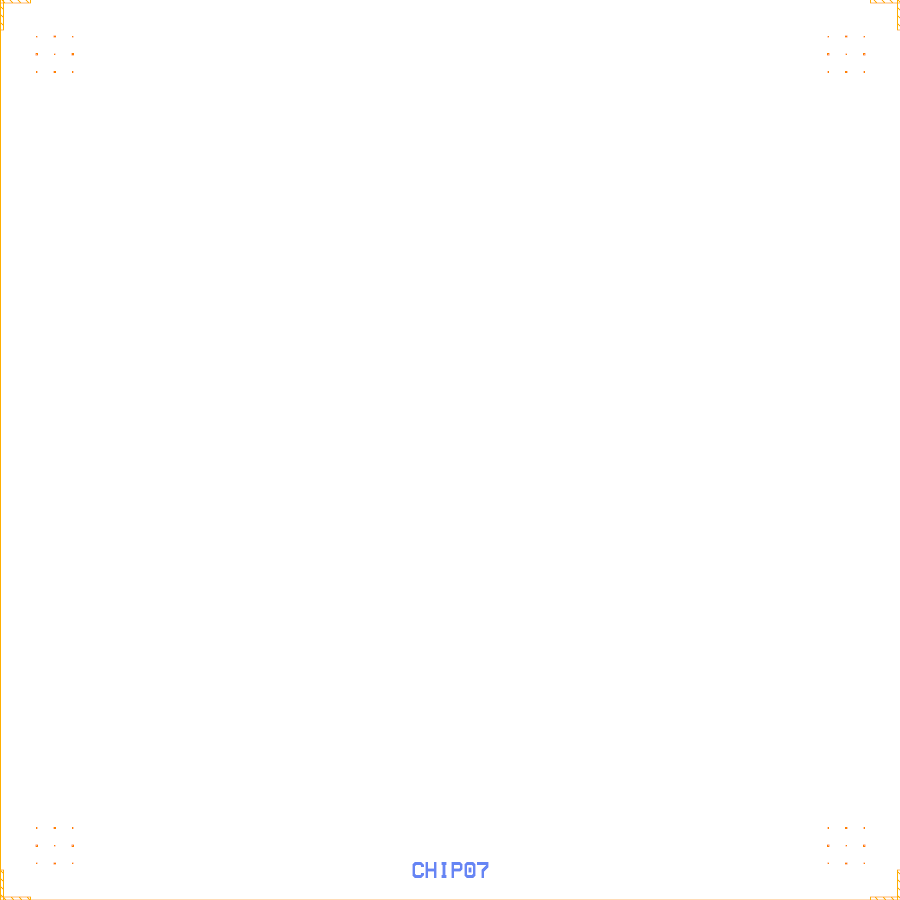

WindowsPath('build/legacy_steps/chip_07_resonators_1_frame.png')

In [4]:
d = Designer(ID, box=(0, 0, L.W, L.H), chip={"name_chip": "CHIP07", "cheese": "chip"}, live=LIVE)
print(d.design.chip.box, d.design.pdk)
L.step_snapshot(d, "1_frame")

## 4 · Pads (PDK pad rule) and the feedline

The two "Connector Pad 2" bond pads (`BondPad`: 400 × 450 µm pad, 450 µm taper, 225 µm ground gap, square
corners) terminate the feedline. The left pad goes at the legacy feedline end (−2625, 0) with the legacy
rotation (rot 3), and `edge="auto"` slides it perpendicular to its nearest die edge until the outer edge of its
etch is **`pad_edge` = 100 µm** (`get_pdk().frame.pad_edge`, the design-area margin) from the die edge: the PDK pad rule,
which wins over the original (whose pads reached the die edge).

The feedline (`CpwSegment`, 10/6 µm) then snaps onto the left pad's port and is as long as the rule leaves on a
symmetric chip (die width − 2 × the pad port's x), and the right pad snaps onto its far end, as in the source
(pads snapped to the feedline ends). Snaps are real connections: pad, feedline and pad are one conductor in the
netlist. `L.edge_gaps` measures both pads from the built etch. The feedline is 200 µm shorter than the legacy
5250 µm (5050 µm); the six resonator couplers sit at fixed legacy positions beside it (all inside its span), so the coupling is unchanged.

pad etch → die edge (µm): {'PL': 100.0, 'PR': 100.0}
feedline 5050 µm (legacy 5250 µm)


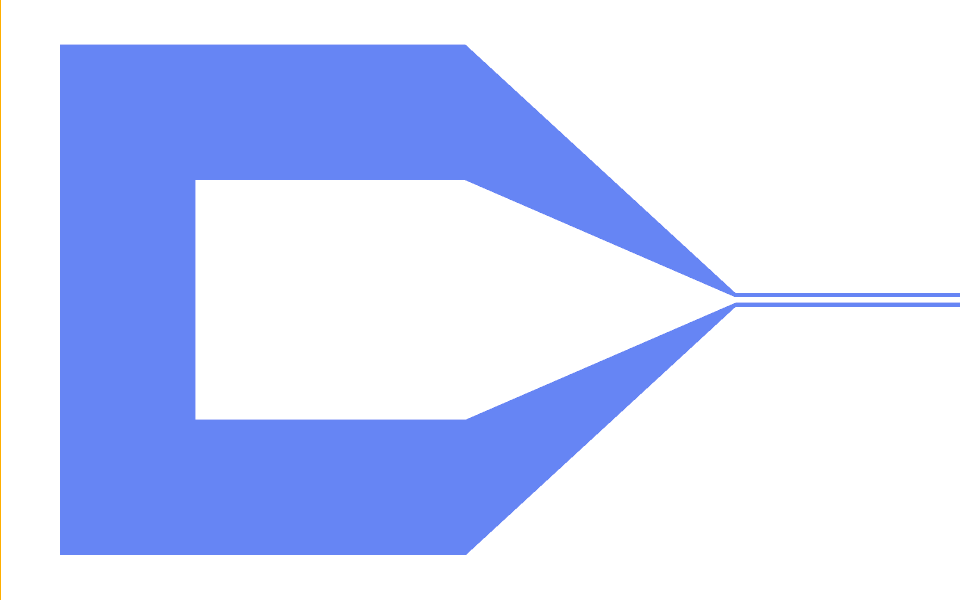

WindowsPath('build/legacy_steps/chip_07_resonators_2_pads.png')

In [5]:
PAD = dict(pad_width=400, pad_gap=225, pad_height=450, taper_length=450, a=10, b=6, rounded=False)  # "Connector Pad 2"
d.add("PL", "BondPad", **L.place(-LB.C07_PAD_X, 0, 3), edge="auto", **PAD)       # legacy (−2625, 0), rot 3
x_a = C.port_xy(d, "PL.a")[0]
FEED = LB.C07_FEED | {"length": round(L.W - 2 * x_a, 3)}                      # symmetric chip
with d.batch():
    d.add("FL", "CpwSegment", snap="a", to="PL.a", **L.cpw_segment(**FEED))
    d.add("PR", "BondPad", snap="a", to="FL.b", **PAD)                         # legacy (+2625, 0), rot 1
print("pad etch → die edge (µm):", L.edge_gaps(d))
print(f"feedline {FEED['length']:.0f} µm (legacy {LB.C07_FEED['length']} µm)")
L.step_snapshot(d, "2_pads", box=(0, 3250, 1600, 4250), size=(960, 600), width=480)

## 5 · Components: the six λ/4 resonators

Each `CoupledResonator` is the legacy `Coupled Resonator` PCell (`L.coupled_resonator` maps the legacy
parameters): a meandered 10/6 µm λ/4 (`cpw_len`), shorted to ground at the end of a straight coupler
(`clength`) that runs beside the feedline behind a `cgap` µm ground strip, and an open end (`ground=True`: the
PCell's own end cap). `d.couple("K_Rn", "Rn", "FL")` declares the coupler ∥ feedline coupling, which no port
carries; the netlist turns it into a hanger κ element (step 8). `d.targets` stores the source's target
frequencies, so the LOM tables show them next to the simulated values.

| resonator | `cpw_len` (µm) | coupler `clength` / `cgap` (µm) | target (GHz) |
|---|---|---|---|
| R2 | 6200 | 200 / 4 | 5.0 |
| R3 | 5840 | 300 / 4 | 5.25 |
| R6 | 5590 | 400 / 4 | 5.5 |
| R8 | 5200 | 300 / 6 | 6.0 |
| R9 | 4920 | 300 / 4 | 6.25 |
| R12 | 4740 | 600 / 6 | 6.5 |

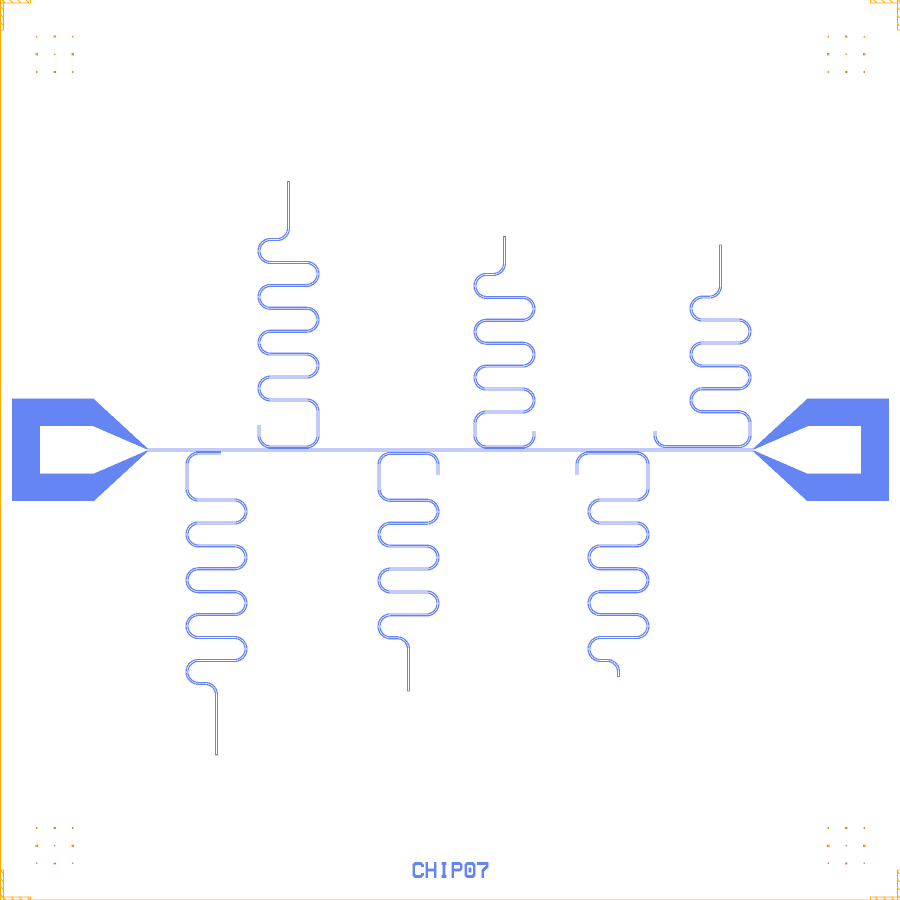

WindowsPath('build/legacy_steps/chip_07_resonators_3_resonators.png')

In [6]:
with d.batch():
    for n, (x, y, mirror, over, f, _m2) in LB.C07_RES.items():
        p = LB.C07_RES_COMMON | over
        d.add(n, "CoupledResonator", **L.place(x, y, 0, mirror), **L.coupled_resonator(**p))
        d.couple(f"K_{n}", n, "FL", note=f"{p['clength']} µm coupler beside the feedline")
d.targets(**{n: {"f_GHz": r[4]} for n, r in LB.C07_RES.items()})
L.step_snapshot(d, "3_resonators")

## 6 · The source's cheese, the labels, and centring

**Cheese — the source's holes and the PDK cheese.** The source etches its own flux-trapping holes: six arrays of two rows of 5 µm
squares (20 µm pitch along the line, 15 µm across) beside the feedline (`FluxHoleArray`, drawn on 1/0). They stay as drawn; the chip's `cheese="chip"` (step 3) adds the PDK squares over the rest of the die, at least 4 µm from the 3/0 keep-outs (which cover the hole arrays too), so no PDK hole touches a structure or a flux hole. The pad rule moved the pads 100 µm in, over the ends of the first and last rows: `L.clip_holes` keeps only the holes beside the feedline (on the legacy grid), so FH0 and FH5 lose 2 and 4 holes per row (a hole in a pad's taper would cut the pad).
**Labels:** the chip label and the six frequency labels (`TextLabel`, the legacy `TextGenerator` font).
No routes: like the legacy chip it is drawn from fixed cells whose ports touch.

**Centring (PDK placement rule).** `L.center_circuit` measures the circuit (instances and routes; the free text
labels are excluded from the measure because the source places them relative to the die, but they move with
everything) and shifts the design so it sits in the middle of the die. Then the design is saved: the JSON is
what every later step reads.

FH0: 2 of 44 holes per row lay under the moved pads: dropped
FH5: 4 of 45 holes per row lay under the moved pads: dropped
centring shift (µm): (0.0, 150.5) | feedline y = 3900.5 | <Designer chip_07_resonators: 22 instances, 0 routes, live=False> → examples\designs\legacy\chip_07_resonators.json


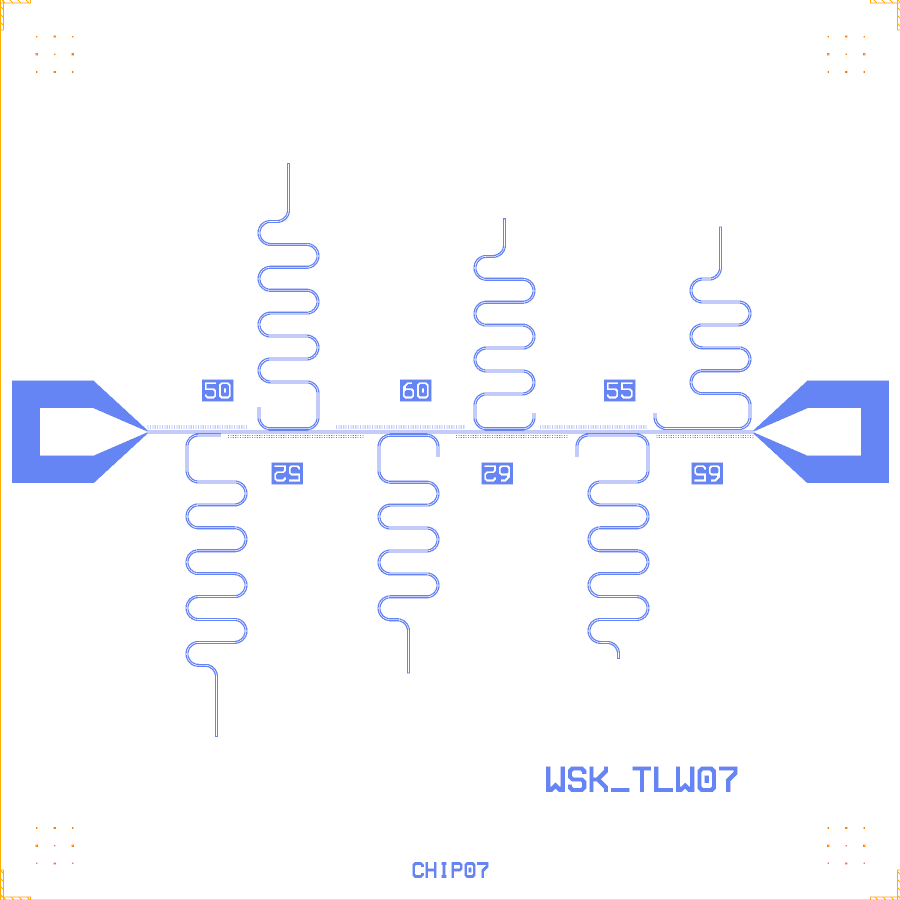

WindowsPath('build/legacy_steps/chip_07_resonators_4_centred.png')

In [7]:
X_END = FEED["length"] / 2                 # feedline ends (legacy frame): the pads start here
with d.batch():
    for k, (x, y, length) in enumerate(LB.C07_HOLES):
        x0, nx = L.clip_holes(x, int(length / 20), -X_END, X_END)   # FH0 / FH5: no holes under the moved pads
        d.add(f"FH{k}", "FluxHoleArray", at=L.at(x0, y), hole_size=5, pitch_x=20, pitch_y=15, nx=nx, ny=2)
        if nx < int(length / 20):
            print(f"FH{k}: {int(length / 20) - nx} of {int(length / 20)} holes per row lay under the moved pads: dropped")
    for name, text, mag, inv, x, y, rot in LB.C07_TEXT:
        d.add(name, "TextLabel", **L.place(x, y, rot), text=text, mag=mag, inverted=inv)
for n in LB.C07_RES:                       # FEM groups: each resonator with the feedline (+ its pads, added by the export)
    d.sim_group(n, [n, "FL"], margin_um=300, analyses=["q3d_cmatrix", "eigenmode_epr"])
SHIFT = L.center_circuit(d)
DESIGN = d.save(OUT / f"{ID}.json")
print("centring shift (µm):", SHIFT, "| feedline y =", round(C.port_xy(d, "FL.a")[1], 1), "|", d, "→", DESIGN)
L.step_snapshot(d, "4_centred")

## 7 · DRC

`d.drc()` builds the chip and checks it: **errors** (overlapping etch of unrelated cells, ports not landing,
parts outside the chip) must be fixed; **warnings** are reported for a person to judge (a dangling open end,
two cells' bounding boxes touching); **PDK design warnings** (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`) flag
values outside the PDK margins — they are never retuned for, only listed. `C.pdk_report(d)` summarises the
PDK checks: cheese source, content centring, junction types and the design warnings.

Expected: zero errors; warnings `dangling_port` on the six resonator `end`s (the open ends: nothing connects there
by design) and one `overlap` of the bounding boxes of `FH1` and `R2` (R2's coupler bbox reaches the hole row; no
hole comes within 1 µm of R2's etch, and the XOR in step 14 confirms the legacy placement). No PDK design
warnings (no `pad_edge` any more; no junctions). `pdk_report`: cheese "PDK cheese over the whole die (drawn in the build)", content
centre (+0, +0) µm (free text labels are left out of the measure). The `overlap` warnings FH0/PL and FH5/PR that the 100 µm pads first caused are gone with the clipped rows.

In [8]:
drc = d.drc()
print(drc)
display(Markdown(C.pdk_report(d)))

warning dangling_port R12.end is not connected (no route or snap)
warning dangling_port R2.end is not connected (no route or snap)
warning dangling_port R3.end is not connected (no route or snap)
warning dangling_port R6.end is not connected (no route or snap)
warning dangling_port R8.end is not connected (no route or snap)
warning dangling_port R9.end is not connected (no route or snap)
warning overlap       FH1 and R2 overlap


| check | value |
|---|---|
| cheese | the original design's own (or none) |
| content centre − die centre | (+0, +0) µm |
| junction types | — |
| PDK design warnings | 0 (none) |

## 8 · Netlist and LOM

`d.lom()` turns the layout into a lumped-element circuit. Every component has a LOM model that maps its ports
to circuit nodes: the feedline and both pads are **one node** (one conductor) with a 50 Ω port at each pad;
each resonator is a λ/4 `TLres` (drawn length, ε_eff of the 10/6 µm CPW on sapphire, shorted at the coupler)
from its node to ground, plus a `HANGER` κ element to the feedline (from `clength` / `cgap`, declared by
`d.couple`). The six unconnected ports are the resonators' open ends.

In [9]:
lb = d.lom()
C.show_netlist(lb)
print(C.lom_summary(lb))

**8 nodes · 14 branches · 0 controls · 6 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `FL.line` | `PL.pad`, `FL.line`, `PR.pad` |
| `R2.res` | `R2.res` |
| `R3.res` | `R3.res` |
| `R6.res` | `R6.res` |
| `R8.res` | `R8.res` |
| `R9.res` | `R9.res` |
| `R12.res` | `R12.res` |

| branch | type | nodes | estimate |
|---|---|---|---|
| `Port_PL` | R | `FL.line` – `gnd` | 50 Ω |
| `Port_PR` | R | `FL.line` – `gnd` | 50 Ω |
| `R2` | TLres | `R2.res` – `gnd` | lambda/4, 6200 µm, 5.082 GHz |
| `K_R2` | HANGER | `R2.res` – `FL.line` | κ 0.0544 MHz (L 200 µm) |
| `R3` | TLres | `R3.res` – `gnd` | lambda/4, 5840 µm, 5.395 GHz |
| `K_R3` | HANGER | `R3.res` – `FL.line` | κ 0.146 MHz (L 300 µm) |
| `R6` | TLres | `R6.res` – `gnd` | lambda/4, 5590 µm, 5.637 GHz |
| `K_R6` | HANGER | `R6.res` – `FL.line` | κ 0.296 MHz (L 400 µm) |
| `R8` | TLres | `R8.res` – `gnd` | lambda/4, 5200 µm, 6.059 GHz |
| `K_R8` | HANGER | `R8.res` – `FL.line` | κ 0.139 MHz (L 300 µm) |
| `R9` | TLres | `R9.res` – `gnd` | lambda/4, 4920 µm, 6.404 GHz |
| `K_R9` | HANGER | `R9.res` – `FL.line` | κ 0.245 MHz (L 300 µm) |
| `R12` | TLres | `R12.res` – `gnd` | lambda/4, 4740 µm, 6.647 GHz |
| `K_R12` | HANGER | `R12.res` – `FL.line` | κ 0.726 MHz (L 600 µm) |

**Unconnected ports:** `R12.end`, `R2.end`, `R3.end`, `R6.end`, `R8.end`, `R9.end`

{'nodes': 7, 'branches': 14, 'controls': 0, 'unconnected': 6}


## 9 · LOM simulation

Each resonator with the feedline and its two 50 Ω pads (QuCat normal mode and κ, QuTiP-dressed f_r;
`C.simulate_groups` simulates one sub-circuit per group, which keeps QuCat fast). The table compares the LOM
with the legacy targets and with design 14's simulated calibration table, which lists five of these six
lengths (`_legacy_b.D14_SIM_TABLE`).

In [10]:
results = C.simulate_groups(d, {n: [n, "FL", "PL", "PR"] for n in LB.C07_RES})
display(Markdown(C.groups_md(results, d.data["targets"])))
sim14 = {L_um: f for _, L_um, f in LB.D14_SIM_TABLE}
rows = ["| resonator | cpw_len (µm) | clength / cgap (µm) | target (GHz) | design-14 simulation (GHz) | LOM bare λ/4 (GHz) "
        "| LOM loaded (GHz) | κ (MHz) |", "|---|---|---|---|---|---|---|---|"]
for n, (x, y, mirror, over, f, _m2) in LB.C07_RES.items():
    p = LB.C07_RES_COMMON | over
    sim = sim14.get(p["cpw_len"])
    rows.append(f"| {n} | {p['cpw_len']} | {p['clength']} / {p['cgap']} | {f:g} | {'–' if sim is None else f'{sim:.3f}'} | "
                f"{lb.model.branches[n].value['f_GHz']:.3f} | {results[n].params[f'{n}.f_GHz']:.3f} | "
                f"{results[n].params[f'{n}.kappa_MHz']:.3g} |")
display(Markdown("\n".join(rows)))

| group | qubit | f_q (GHz) | α (MHz) | resonator | f_r (GHz) | κ (MHz) | χ (MHz) |
|---|---|---|---|---|---|---|---|
| R2 | – | – | – | R2 | 5.0682 (5) | 0.0538 | – |
| R3 | – | – | – | R3 | 5.3719 (5.25) | 0.144 | – |
| R6 | – | – | – | R6 | 5.6027 (5.5) | 0.289 | – |
| R8 | – | – | – | R8 | 6.0352 (6) | 0.137 | – |
| R9 | – | – | – | R9 | 6.3713 (6.25) | 0.24 | – |
| R12 | – | – | – | R12 | 6.59 (6.5) | 0.701 | – |

| resonator | cpw_len (µm) | clength / cgap (µm) | target (GHz) | design-14 simulation (GHz) | LOM bare λ/4 (GHz) | LOM loaded (GHz) | κ (MHz) |
|---|---|---|---|---|---|---|---|
| R2 | 6200 | 200 / 4 | 5 | – | 5.082 | 5.068 | 0.0538 |
| R3 | 5840 | 300 / 4 | 5.25 | 4.616 | 5.395 | 5.372 | 0.144 |
| R6 | 5590 | 400 / 4 | 5.5 | 5.787 | 5.637 | 5.603 | 0.289 |
| R8 | 5200 | 300 / 6 | 6 | 6.188 | 6.059 | 6.035 | 0.137 |
| R9 | 4920 | 300 / 4 | 6.25 | 6.525 | 6.404 | 6.371 | 0.24 |
| R12 | 4740 | 600 / 6 | 6.5 | 6.761 | 6.647 | 6.590 | 0.701 |

**Reading the numbers** (LOM of this run). The bare λ/4 (drawn length, ε_eff of the 10/6 µm CPW on sapphire
ε_r 10.25) sits 0.06–0.15 GHz *above* the targets written into this chip, i.e. the targets assumed a slightly
longer effective length than the drawn one (all bare: the legacy lengths were simulated without the claws,
Design 14's simulated values for 5590, 5200, 4920 and 4740 µm are 1.7–2.6 % above the LOM (the
5840 µm entry, 4.616 GHz, is the one design 14 excludes as inconsistent). The hanger loading pulls each f_r a
further 15–60 MHz down. κ follows clength and cgap (R12: 600 µm at 6 µm gives the largest, ≈ 0.7 MHz).

## 10 · FEM: send the job

Each sim group is cut out of the chip (its instances plus a margin of ground), with the PDK stack (sapphire
650 µm, ε_r 10.25) and **without cheese** (simulation exports never have it), and written as a job folder
under `build/jobs/` (`C.export_sims` → `build_simulation` + `export_job`): a Q3D C-matrix job by default,
`analysis="eigenmode_epr"` for the eigenmode / EPR job. With `RUN_FEM = True` and AEDT 2024 R1 (v241) or
newer on this machine, `L.fem_send` solves each job in a **new batch, non-graphical** AEDT
(`sim_tools.hfss.solve_job`) — it never touches an AEDT window you have open. The default here is
`False`: export only.

Here: one Q3D C-matrix job per resonator with the feedline. The bond pads that terminate the feedline (`PL`,
`PR`) join each group with their 50 Ω lumped ports, so the feedline is never floating. Each λ/4 resonator is
shorted to ground at its coupler end, so its centre conductor is part of ground: the only C-matrix net is the
feedline (named `PL.pad` after the first port on it), and the hanger coupling shows up as the eigenmode Q (κ)
of the loaded resonator (`analysis="eigenmode_epr"`).

In [11]:
RUN_FEM = False                       # True: solve the exported jobs here (AEDT 2024 R1+, batch)
jobs = C.export_sims(DESIGN)
display(Markdown(C.jobs_md(jobs)))
display(Markdown(L.fem_send(jobs, run=RUN_FEM)))

| group | job | ports (number · kind · name) | C-matrix nets |
|---|---|---|---|
| R2 | `build/jobs/chip_07_resonators_R2_q3d_cmatrix` | 1 · lumped · `PL.pad`<br>2 · lumped · `PR.pad` | `PL.pad`, `floating1`, `floating2`, `floating3`, `floating4`, `floating5`, `floating6`, `floating7`, `floating8`, `floating9`, `floating10`, `floating11`, `floating12`, `floating13`, `floating14` |
| R3 | `build/jobs/chip_07_resonators_R3_q3d_cmatrix` | 1 · lumped · `PL.pad`<br>2 · lumped · `PR.pad` | `PL.pad`, `floating1`, `floating2`, `floating3`, `floating4`, `floating5`, `floating6`, `floating7`, `floating8`, `floating9`, `floating10`, `floating11`, `floating12`, `floating13`, `floating14` |
| R6 | `build/jobs/chip_07_resonators_R6_q3d_cmatrix` | 1 · lumped · `PL.pad`<br>2 · lumped · `PR.pad` | `PL.pad`, `floating1`, `floating2`, `floating3`, `floating4`, `floating5`, `floating6`, `floating7`, `floating8`, `floating9`, `floating10`, `floating11`, `floating12`, `floating13`, `floating14` |
| R8 | `build/jobs/chip_07_resonators_R8_q3d_cmatrix` | 1 · lumped · `PL.pad`<br>2 · lumped · `PR.pad` | `PL.pad`, `floating1`, `floating2`, `floating3`, `floating4`, `floating5`, `floating6`, `floating7`, `floating8`, `floating9`, `floating10`, `floating11`, `floating12`, `floating13`, `floating14` |
| R9 | `build/jobs/chip_07_resonators_R9_q3d_cmatrix` | 1 · lumped · `PL.pad`<br>2 · lumped · `PR.pad` | `PL.pad`, `floating1`, `floating2`, `floating3`, `floating4`, `floating5`, `floating6`, `floating7`, `floating8`, `floating9`, `floating10`, `floating11`, `floating12`, `floating13`, `floating14` |
| R12 | `build/jobs/chip_07_resonators_R12_q3d_cmatrix` | 1 · lumped · `PL.pad`<br>2 · lumped · `PR.pad` | `PL.pad`, `floating1`, `floating2`, `floating3`, `floating4`, `floating5`, `floating6`, `floating7`, `floating8`, `floating9`, `floating10`, `floating11`, `floating12`, `floating13`, `floating14` |

AEDT on this machine: `C:\Program Files\AnsysEM\v241\Win64\ansysedt.exe` (v241)

`RUN_FEM = False`: 6 job(s) exported, none solved. Set `RUN_FEM = True` to solve them here (batch, non-graphical), or run `qcc sim run <job>` on a machine with AEDT 2024 R1+.

## 11 · Bring the results back

A solved job leaves `results/results.json` in its folder. `fill(model, DESIGN, job)` then replaces the LOM's
component estimates by the FEM C-matrix, matched by net name (the net names are the ones in the job table
above), and the LOM is simulated again with them. `L.fem_bring_back` does this for every job that has
results and says which have none yet.

Here no job has been solved yet (no `results.json` under `build/jobs/chip_07_resonators_*`), so the cell says so.
With results, the eigenmode jobs would give each resonator's loaded f_r and Q next to the LOM's.

In [12]:
display(Markdown(L.fem_bring_back(d, DESIGN, jobs, groups=None)))

No FEM results yet for 6 job(s) (`build/jobs/chip_07_resonators_R2_q3d_cmatrix`, `build/jobs/chip_07_resonators_R3_q3d_cmatrix`, `build/jobs/chip_07_resonators_R6_q3d_cmatrix`, `build/jobs/chip_07_resonators_R8_q3d_cmatrix`, …). After a solve each job holds `results/results.json`; this cell then fills the LOM with the extracted C-matrix (`fill(model, DESIGN, job)`) and shows the estimate next to the FEM value per capacitance, and f_q / α / f_r / χ re-simulated with them.

## 12 · Iterate: change one property and re-simulate

The design is data, so a variant is a copy with one parameter changed. Here R12's coupler is shortened from
600 to 400 µm (`clength`): the hanger κ falls roughly with the square of the coupling length, while f_r moves
only slightly (the coupler is part of the λ/4). The copy is not saved; the chip stays as built.

In [13]:
d2 = Designer.load(DESIGN, live=False, verbose=False)      # a copy of the saved design
d2["R12"].set(clength=400)
sel = {"R12": ["R12", "FL", "PL", "PR"]}
after = C.simulate_groups(d2, sel)["R12"]
display(Markdown(L.compare_md(results["R12"], after, keys=["R12.f_GHz", "R12.kappa_MHz"],
                              label=("clength 600 µm", "clength 400 µm"))))

| parameter | clength 600 µm | clength 400 µm | Δ |
|---|---|---|---|
| `R12.f_GHz` | 6.59 | 6.6088 | +0.01884 |
| `R12.kappa_MHz` | 0.70101 | 0.31746 | -0.3835 |

## 13 · Build and export

The design is saved as JSON (`DESIGN`, step 6): it is the source of truth — the layout, the netlist, the
FEM jobs and the mask are all made from it. The **fab mask** (`export_fab`) keeps only the PDK fab layers
(1/0 etch, 2/0 + 4/0 junction fingers, 3/0 second-metal keep-out, 50–53/0 spacer, 100/0 boundary, 1000/0 +
1001/0 markers), rounds the corners (radius ∝ each polygon's shortest dimension) and keeps the build's
cheese. **Simulation exports** never carry cheese; they drop airbridges unless asked
(`build_simulation(..., airbridges=True)`); the legacy chips have none.

Here: `cheese=True` (the default) keeps the build's cheese: the PDK squares over the whole die (`cheese_source` "build") and the source's flux holes, which are part of 1/0 (drawn by `FluxHoleArray`).

The same from a shell:

```
qcc build examples/designs/legacy/chip_07_resonators.json                    # layout → build/chip_07_resonators.oas
qcc mask  examples/designs/legacy/chip_07_resonators.json          # fab mask with the PDK rules
qcc sim build examples/designs/legacy/chip_07_resonators.json -g <group> -a q3d_cmatrix   # one FEM job (step 10)
qcc sim run build/jobs/chip_07_resonators_<group>_q3d_cmatrix              # solve it (AEDT 2024 R1+)
```

In [14]:
display(Markdown(L.fab_md(d)))

Fab mask: `build/chip_07_resonators_fab.oas` · cheese source **none** (0 PDK-band holes) · corner rounding on

| fab layer | PDK name | polygons |
|---|---|---|
| 1/0 | M1 | 607 |
| 3/0 | M3 | 11 |
| 100/0 | CHIP_BOUNDARY | 1 |
| 1000/0 | MARKERS_DICING | 4 |
| 1001/0 | MARKERS_ALIGN | 36 |

## 14 · Snapshots and comparison with the legacy geometry

The full chip; zooms on a resonator's coupler (R12, 600 µm at 6 µm, with the flux holes) and on a resonator end
(no qubits or junctions on this chip); then the legacy chip drawn by the author's own PCells (read-only harness,
moved by the centring shift) and the per-instance XOR on 1/0 — first against the legacy exactly as drawn
(R8/R9/R12 on the swapped layers), then with those three on the default layers. Expected XOR: 0 on the
resonators, holes and labels; the pads (moved 100 µm in by the pad rule), the feedline (200 µm shorter) and FH0 / FH5 (the holes under the moved pads dropped) differ
by design.

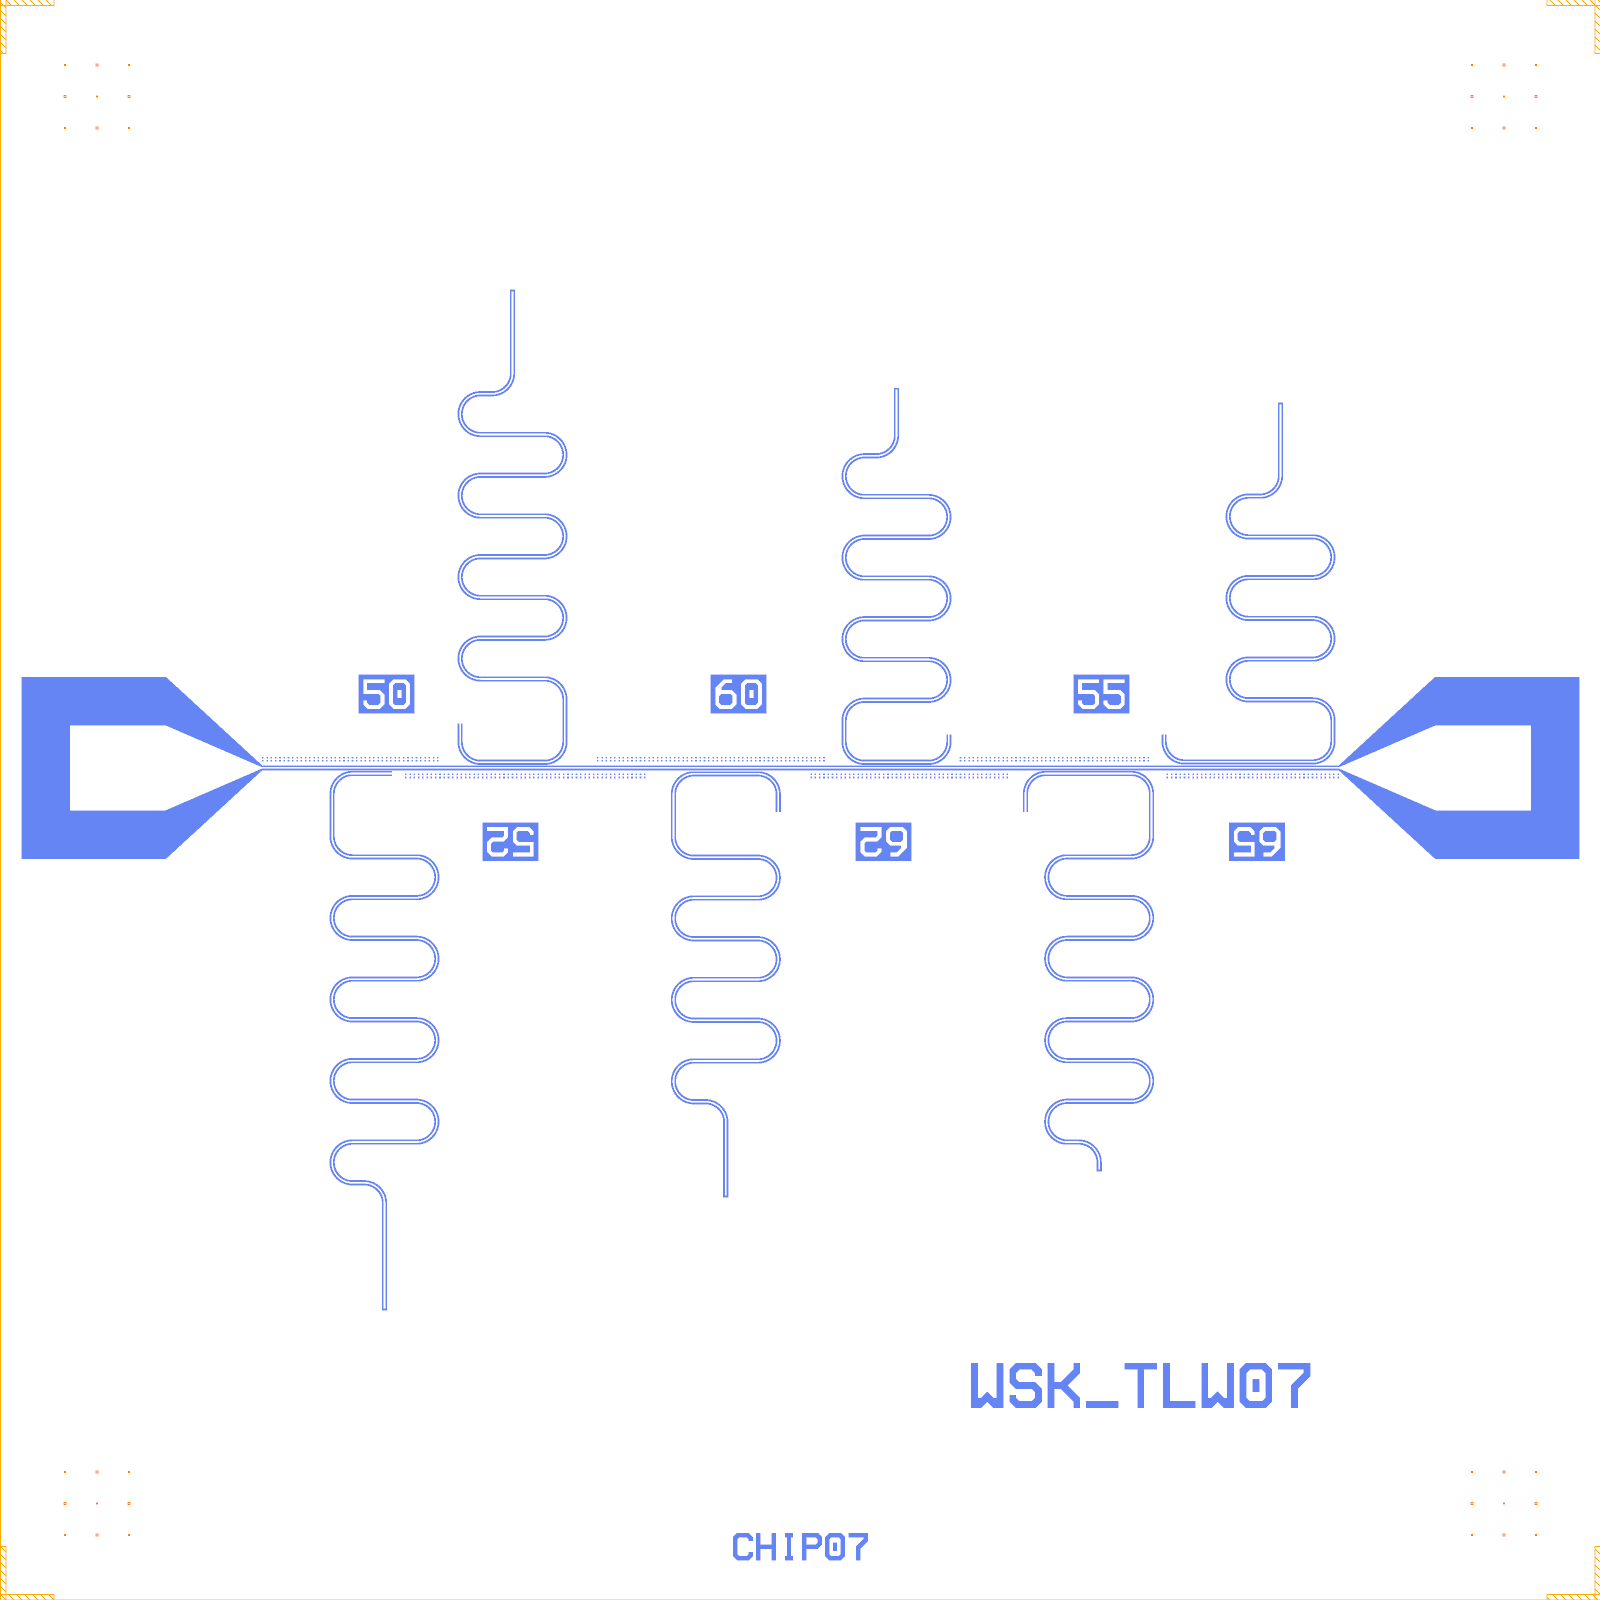

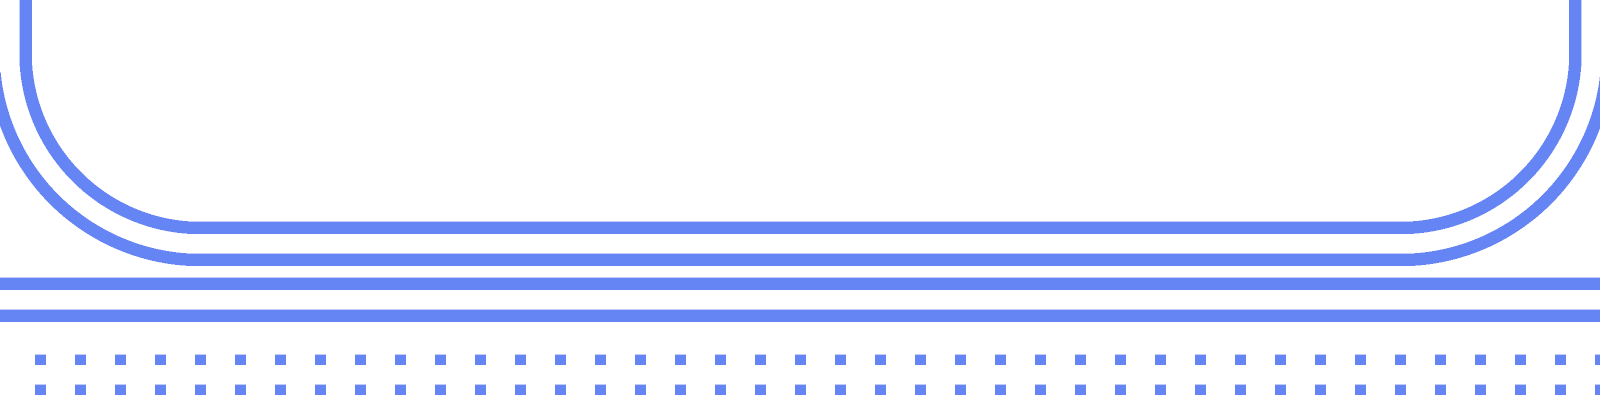

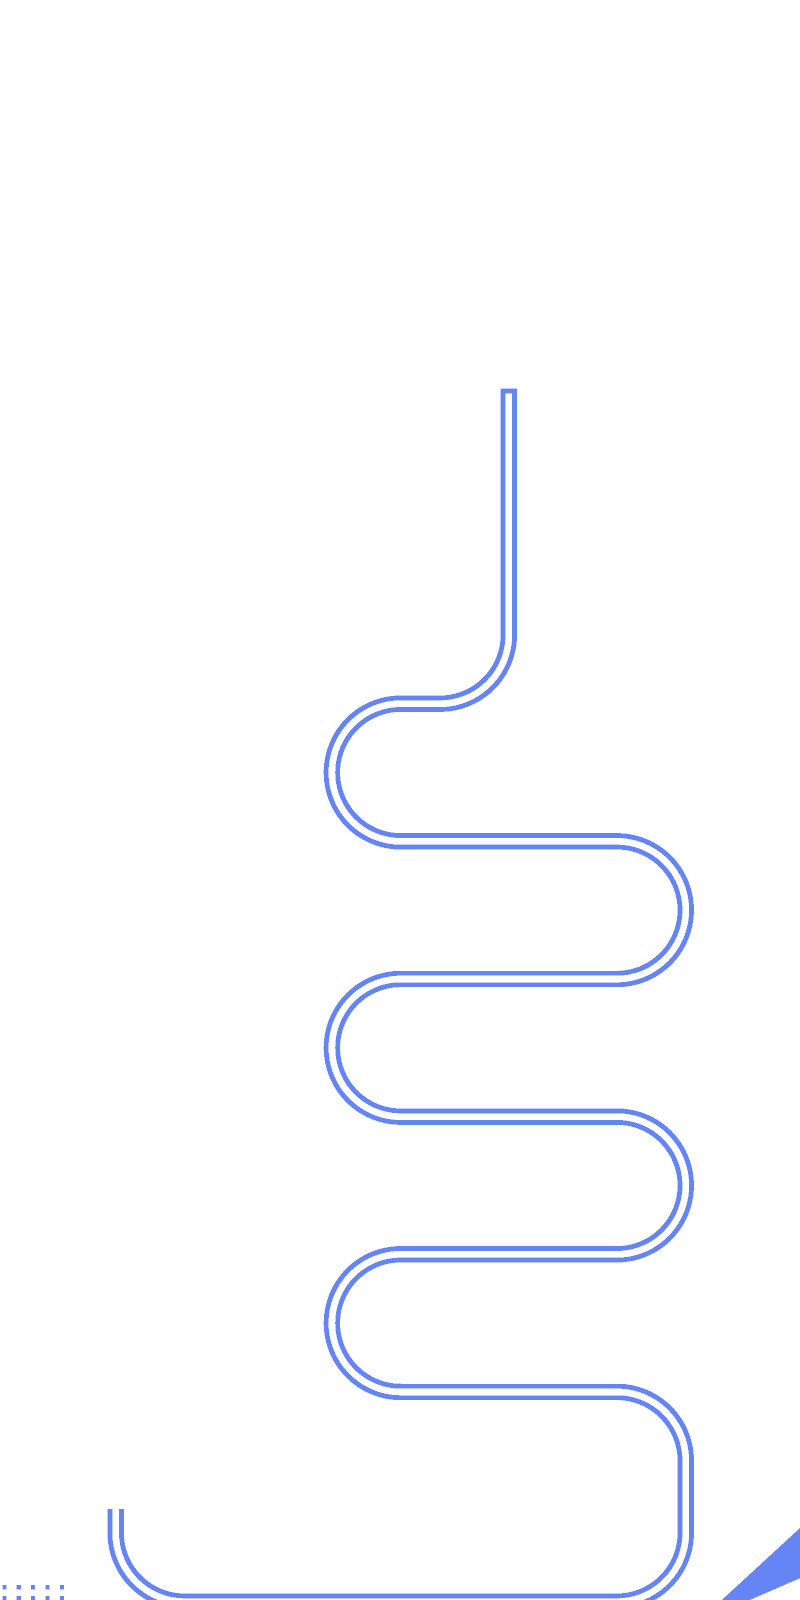

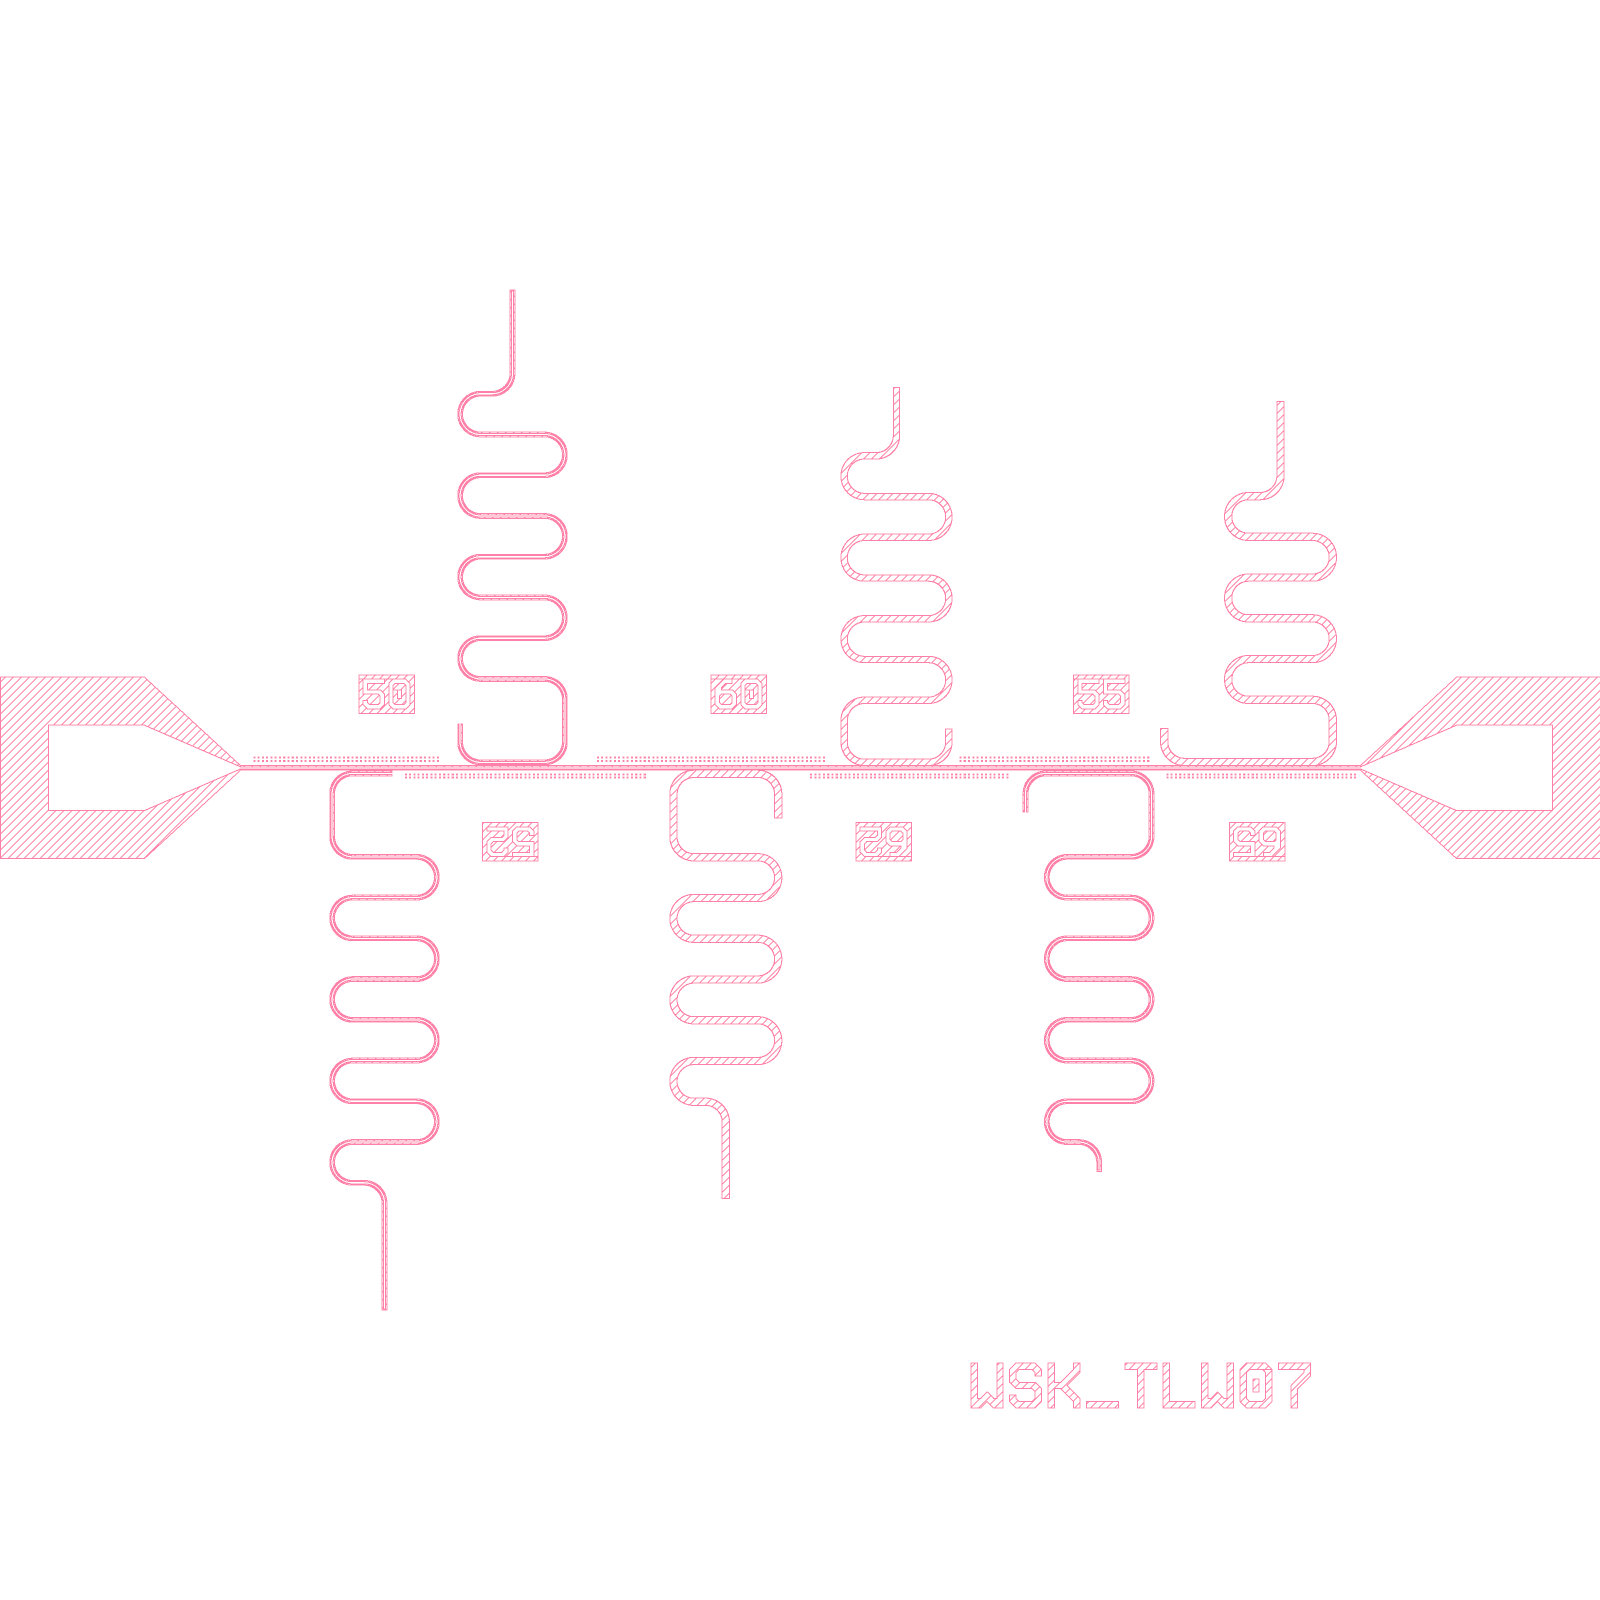

**XOR against the legacy as drawn** (R8 / R9 / R12: legacy 1/0 is their second-metal envelope)

| instance | legacy etch (µm²) | rebuilt etch (µm²) | XOR (µm²) | XOR / legacy |
|---|---|---|---|---|
| FL | 63000 | 60766 | 2233.8 | 3.55% |
| PL | 497700 | 491633 | 227540.5 | 45.72% |
| PR | 497700 | 491633 | 227540.5 | 45.72% |
| R2 | 74751 | 74751 | 0.0 | 0.00% |
| R3 | 70031 | 70031 | 0.0 | 0.00% |
| R6 | 67031 | 67031 | 0.0 | 0.00% |
| R8 | 177615 | 62327 | 115288.0 | 64.91% |
| R9 | 148199 | 58991 | 89208.0 | 60.19% |
| R12 | 161975 | 56808 | 105168.0 | 64.93% |
| FH0 | 2200 | 2222 | 172.3 | 7.83% |
| FH1 | 2850 | 2850 | 0.0 | 0.00% |
| FH2 | 2700 | 2700 | 0.0 | 0.00% |
| FH3 | 2350 | 2350 | 0.0 | 0.00% |
| FH4 | 2250 | 2250 | 0.0 | 0.00% |
| FH5 | 2250 | 2882 | 835.7 | 37.14% |
| LBL_CHIP | 119025 | 119025 | 0.0 | 0.00% |
| LBL_50 | 31050 | 31050 | 0.0 | 0.00% |
| LBL_52 | 31850 | 31850 | 0.0 | 0.00% |
| LBL_60 | 31100 | 31100 | 0.0 | 0.00% |
| LBL_62 | 31900 | 31900 | 0.0 | 0.00% |
| LBL_55 | 31700 | 31700 | 0.0 | 0.00% |
| LBL_65 | 31750 | 31750 | 0.0 | 0.00% |

**XOR with R8 / R9 / R12 on the default layers**

| instance | legacy etch (µm²) | rebuilt etch (µm²) | XOR (µm²) | XOR / legacy |
|---|---|---|---|---|
| FL | 63000 | 60766 | 2233.8 | 3.55% |
| PL | 497700 | 491633 | 227540.5 | 45.72% |
| PR | 497700 | 491633 | 227540.5 | 45.72% |
| R2 | 74751 | 74751 | 0.0 | 0.00% |
| R3 | 70031 | 70031 | 0.0 | 0.00% |
| R6 | 67031 | 67031 | 0.0 | 0.00% |
| R8 | 62327 | 62327 | 0.0 | 0.00% |
| R9 | 58991 | 58991 | 0.0 | 0.00% |
| R12 | 56808 | 56808 | 0.0 | 0.00% |
| FH0 | 2200 | 2222 | 172.3 | 7.83% |
| FH1 | 2850 | 2850 | 0.0 | 0.00% |
| FH2 | 2700 | 2700 | 0.0 | 0.00% |
| FH3 | 2350 | 2350 | 0.0 | 0.00% |
| FH4 | 2250 | 2250 | 0.0 | 0.00% |
| FH5 | 2250 | 2882 | 835.7 | 37.14% |
| LBL_CHIP | 119025 | 119025 | 0.0 | 0.00% |
| LBL_50 | 31050 | 31050 | 0.0 | 0.00% |
| LBL_52 | 31850 | 31850 | 0.0 | 0.00% |
| LBL_60 | 31100 | 31100 | 0.0 | 0.00% |
| LBL_62 | 31900 | 31900 | 0.0 | 0.00% |
| LBL_55 | 31700 | 31700 | 0.0 | 0.00% |
| LBL_65 | 31750 | 31750 | 0.0 | 0.00% |

max XOR without pads, feedline and FH0 / FH5 (default layers): 0.0 µm²


In [15]:
dy = SHIFT[1]
C.show_snapshot(d, OUT / f"{ID}.png", box=(0, 0, 7500, 7500), size=(1600, 1600))
C.show_snapshot(d, OUT / f"{ID}_coupler.png", box=(5450, 3700 + dy, 6250, 3900 + dy), size=(1600, 400), width=640)  # R12 coupler
C.show_snapshot(d, OUT / f"{ID}_resonator.png", box=(5300, 3780 + dy, 6400, 6000 + dy), size=(800, 1600), width=320)  # R12
if L.legacy_available():
    from quantcore_circuits.live.snapshot import snapshot
    ref = L.shift_reference(LB.chip07_reference(second_metal=True), *SHIFT)
    snapshot(ref.write("build/legacy_b/chip_07_resonators_legacy.oas"), OUT / f"{ID}_legacy.png",
             box=(0, 0, 7500, 7500), size=(1600, 1600))
    display(Image(filename=str(OUT / f"{ID}_legacy.png"), width=640))
    table, xor = L.xor_table(d, ref)
    display(Markdown("**XOR against the legacy as drawn** (R8 / R9 / R12: legacy 1/0 is their second-metal "
                     "envelope)\n\n" + table))
    table, xor = L.xor_table(d, L.shift_reference(LB.chip07_reference(second_metal=False), *SHIFT))
    display(Markdown("**XOR with R8 / R9 / R12 on the default layers**\n\n" + table))
    print("max XOR without pads, feedline and FH0 / FH5 (default layers):",
          max(v for k, v in xor.items() if k not in ("PL", "PR", "FL", "FH0", "FH5")), "µm²")
else:
    print("components/ (legacy library) not present: no legacy reference")

## 15 · Summary

- **Matches the source:** the six resonators (XOR 0 on the default layers), the flux-hole rows FH1–FH4 and the labels;
  the LOM f_r are within 1.7–2.6 % of design 14's simulated values for the same lengths.
- **Differs, by the PDK:** pads `pad_edge` = 100 µm from the die edge (feedline 200 µm shorter; FH0 / FH5 stop at the feedline ends), the circuit centred (+150 µm in
  y), the PDK frame and device ID; R8/R9/R12 on 1/0 (the second-metal layer swap is not reproduced: 3/0 is
  derived by the PDK).
- **Cheese:** the PDK cheese over the whole die (`cheese: "chip"`, fab cheese source "build") plus the original's flux holes.
- **Open:** the LOM sits 0.06–0.15 GHz above the written targets (the targets assumed a longer effective
  length); no PDK design warnings.